# 02_Regulated regime training: Hydro-stgat

## 1. Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATConv
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import json
import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Dispositivo de entrenamiento: cpu


## 2. Configuration and hyperparameters

In [2]:
CFG = dict(
    npz_path           = 'dataset_PI_STGAT_regulado.npz',
    metadata_path      = 'metadata_PI_STGAT_regulado.json',
    pretrained_weights = 'best_pi_stgat_lagged.pt',

    hidden_dim         = 128,
    num_heads          = 2,
    num_layers         = 1,
    max_lag            = 30,   
    window_gru         = 15,   
    static_dim_nat     = 12,  
    static_dim_full    = 17,  
    dropout            = 0.1,

    # Phase 1:  RegulationModule (encoder frozen)
    lr_phase1          = 1e-3,
    epochs_phase1      = 25,

    # Phase 2: fine-tuning 
    lr_encoder_phase2  = 1e-5,  # very low to not destroy information
    lr_reg_phase2      = 5e-4,
    epochs_phase2      = 75,
    patience           = 12,

    # Loss function weigths
    lambda_aforo       = 1.0,   # obserde
    lambda_sim         = 0.05,  # simulation
)

import os
if not os.path.exists(CFG['pretrained_weights']):
    raise FileNotFoundError(
        f"Checkpoint not found: {CFG['pretrained_weights']}\n"
        "Copy best_pi_stgat_lagged_tunned.pt in directory."
    )
print(f'Checkpoint found: {CFG["pretrained_weights"]}')
print(f'max_lag={CFG["max_lag"]}  hidden_dim={CFG["hidden_dim"]}  '
      f'window_gru={CFG["window_gru"]}')

Checkpoint encontrado: best_pi_stgat_lagged_tunned.pt
max_lag=30  hidden_dim=128  window_gru=30


## 3. Hydrological metrics

In [3]:
def calculate_nse(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    denom = np.sum((y_true - np.mean(y_true)) ** 2)
    return 0.0 if denom == 0 else float(1.0 - np.sum((y_true - y_pred)**2) / denom)

def calculate_kge(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    if len(y_true) < 2 or np.std(y_true) == 0 or np.std(y_pred) == 0: return 0.0
    r = np.corrcoef(y_true, y_pred)[0, 1]
    if np.isnan(r): r = 0.0
    alpha = np.std(y_pred) / np.std(y_true)
    beta = np.mean(y_pred) / (np.mean(y_true) if np.mean(y_true) != 0 else 1e-5)
    return float(1.0 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2))

## 4.`RegulatedMonthlyDataset`

In [4]:
class RegulatedMonthlyDataset(Dataset):
    def __init__(self, dynamic_tensor, day_to_month, aforo_tensor, sim_tensor, aforo_mask, dias_por_mes, window_gru, max_lag):
        self.dynamic_tensor = dynamic_tensor  
        self.day_to_month = day_to_month     
        self.aforo_tensor = aforo_tensor      
        self.sim_tensor = sim_tensor          
        self.aforo_mask = aforo_mask        
        self.dias_por_mes = dias_por_mes      
        self.W = max_lag + window_gru
        
        self.month_to_days = defaultdict(list)
        for d_idx, m_idx in enumerate(day_to_month):
            self.month_to_days[m_idx].append(d_idx)
            
        self.valid_months = []
        for m_idx in sorted(self.month_to_days.keys()):
            first_day = self.month_to_days[m_idx][0]
            if first_day >= self.W:
                self.valid_months.append(m_idx)
                
    def __len__(self):
        return len(self.valid_months)
        
    def __getitem__(self, idx):
        m_idx = self.valid_months[idx]
        day_indices = self.month_to_days[m_idx]
        
        start_idx = day_indices[0] - self.W
        end_idx = day_indices[-1] + 1
        
        x_block = self.dynamic_tensor[start_idx:end_idx, :, :]  # [Block_len, N, F]
        x_block = np.transpose(x_block, (1, 0, 2))              # [N, Block_len, F]
        
        return {
            'x_block': torch.tensor(x_block, dtype=torch.float32),
            'm_idx': m_idx,
            'aforo': torch.tensor(self.aforo_tensor[m_idx], dtype=torch.float32),
            'sim': torch.tensor(self.sim_tensor[m_idx], dtype=torch.float32),
            'mask': torch.tensor(self.aforo_mask[m_idx], dtype=torch.bool),
            'dias': self.dias_por_mes[m_idx]
        }

## 5. Models: PISTGATLagged y RegulationModule

In [5]:

class PISTGATLagged(nn.Module):
    def __init__(self, num_climate_features, static_dim, hidden_dim,
                 window_gru, max_lag, num_heads=2, num_layers=1, dropout=0.1):
        super().__init__()
        self.hidden_dim  = hidden_dim
        self.window_gru  = window_gru
        self.max_lag     = max_lag
        self.L           = max_lag + 1

        self.gru = nn.GRU(
            input_size  = num_climate_features,
            hidden_size = hidden_dim,
            num_layers  = num_layers,
            batch_first = True,
            dropout     = dropout if num_layers > 1 else 0.0
        )

        self.gat = GATConv(
            in_channels  = hidden_dim,
            out_channels = hidden_dim // num_heads,
            heads        = num_heads,
            concat       = True
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim + static_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1)
        )

        # lag_weights
        self.lag_weights = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, self.L),
            nn.Softmax(dim=-1)
        )

        # Buffer M_lag 
        self.register_buffer('M_lag', torch.zeros(1))

    def set_mlag(self, M_lag_np):
        self.M_lag = torch.tensor(M_lag_np, dtype=torch.float32)

    def encode_local_runoff(self, x_window, edge_index, x_static):
        """
        x_window : [B, N, W, C]
        Return : r_local [B, N], h_s_3d [B, N, H]
        """
        B, N, W, C = x_window.shape
        _, h_t = self.gru(x_window.reshape(B*N, W, C))
        h_t = h_t.squeeze(0)  # [B*N, H]

        offsets    = torch.arange(B, device=x_window.device) * N
        batched_ei = torch.cat([edge_index + offsets[i] for i in range(B)], dim=1)
        h_s        = F.relu(self.gat(h_t, batched_ei))  # [B*N, H]
        h_s_3d     = h_s.reshape(B, N, -1)                 # [B, N, H]

        x_static_b = x_static.unsqueeze(0).expand(B, -1, -1)  # [B, N, S]
        h_combined = torch.cat([h_s_3d, x_static_b], dim=-1)  # [B, N, H+S]
        r_local    = F.softplus(self.regressor(h_combined)).squeeze(-1)  # [B, N]
        return r_local, h_s_3d

    def forward(self, x_history, edge_index, x_static):
        B, N, W_total, C = x_history.shape
        dev     = x_history.device
        q_accum = torch.zeros(B, N, device=dev)

        for tau in range(self.L):
            start  = self.max_lag - tau
            x_tau  = x_history[:, :, start:start+self.window_gru, :]
            r_tau, h_s = self.encode_local_runoff(x_tau, edge_index, x_static)

            # lag_weights: [B, N, L]
            w_tau  = self.lag_weights(h_s)[:, :, tau]  # [B, N]
            r_weighted = r_tau * w_tau

            M_tau  = self.M_lag[tau].to(dev)
            q_accum += torch.matmul(r_weighted, M_tau.t())

        return torch.log1p(q_accum)


# =============================================================================
# Regulation module
# =============================================================================
class RegulationModule(nn.Module):

    def __init__(self, hidden_dim, static_dim_full=17, num_heads=2, dropout=0.1):
        super().__init__()

        self.extraction_mlp = nn.Sequential(
            nn.Linear(hidden_dim + 1, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),
            nn.Sigmoid()  # alpha ∈ [0, 1]
        )

        self.reservoir_gat = GATConv(
            hidden_dim, hidden_dim // num_heads,
            heads=num_heads, concat=True
        )

        self.reservoir_mlp = nn.Sequential(
            nn.Linear(hidden_dim + static_dim_full, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, h_s, dem, x_static_full, edge_index, is_reservoir):
        """
        h_s          : [B, N, H]   
        dem          : [B, N]      
        x_static_full: [N, 17]     
        is_reservoir : [N]         
        """
        B, N, H = h_s.shape

        ext_in = torch.cat([h_s, dem.unsqueeze(-1)], dim=-1)  # [B, N, H+1]
        alpha  = self.extraction_mlp(ext_in).squeeze(-1)      # [B, N] ∈ [0,1]

        h_flat     = h_s.view(B*N, H)
        offsets    = torch.arange(B, device=h_s.device) * N
        batched_ei = torch.cat([edge_index + offsets[i] for i in range(B)], dim=1)
        h_reg      = F.relu(self.reservoir_gat(h_flat, batched_ei)).view(B, N, H)

        x_static_b = x_static_full.unsqueeze(0).expand(B, -1, -1)  # [B, N, 17]
        res_in     = torch.cat([h_reg, x_static_b], dim=-1)         # [B, N, H+17]
        gamma_raw  = self.reservoir_mlp(res_in).squeeze(-1)         # [B, N]
        is_res_b   = is_reservoir.unsqueeze(0).expand(B, -1)        # [B, N]
        gamma = 1.0 + torch.tanh(gamma_raw) * is_res_b             # [B, N]

        return alpha, gamma


class PIRegulatedSTGAT(nn.Module):

    def __init__(self, base_model, regulation_module):
        super().__init__()
        self.base_model       = base_model
        self.regulation_module = regulation_module

    def forward(self, x_history, edge_index, x_static_nat, x_static_full, dem_history):
        """
        x_history    : [B, N, W_total, C_clima]
        x_static_nat : [N, 12]  
        x_static_full: [N, 17]  
        dem_history  : [B, N, W_total] 
        """
        B, N, W_total, C = x_history.shape
        dev = x_history.device

        is_reservoir = x_static_full[:, 4]  
        q_reg_accum  = torch.zeros(B, N, device=dev)
        q_nat_accum  = torch.zeros(B, N, device=dev)

        for tau in range(self.base_model.L):
            start = self.base_model.max_lag - tau
            end   = start + self.base_model.window_gru

            x_tau   = x_history[:, :, start:end, :]   # [B, N, W_gru, C]
            dem_tau = dem_history[:, :, end - 1]       

     
            r_nat, h_s = self.base_model.encode_local_runoff(
                x_tau, edge_index, x_static_nat
            )

          
            w_tau = self.base_model.lag_weights(h_s)[:, :, tau]  # [B, N]

       
            alpha, gamma = self.regulation_module(
                h_s, dem_tau, x_static_full, edge_index, is_reservoir
            )


            extrac  = torch.clamp(dem_tau * alpha, max=r_nat) 
            r_reg   = F.softplus((r_nat - extrac) * gamma)    

            # 5. Routing con M_lag[tau]
            M_tau = self.base_model.M_lag[tau].to(dev)  # [N, N]
            q_reg_accum += torch.matmul(r_reg   * w_tau, M_tau.t())
            q_nat_accum += torch.matmul(r_nat   * w_tau, M_tau.t())

        return torch.log1p(q_reg_accum), torch.log1p(q_nat_accum)



Clases definidas: PISTGATLagged, RegulationModule, PIRegulatedSTGAT


## 6. Upload dataset

In [6]:
data = np.load(CFG['npz_path'])
with open(CFG['metadata_path'], 'r') as f:
    metadata = json.load(f)
    
edge_index_np      = data['edge_index']        # [2, E]
static_features_np = data['static_features']   # [N, 17]
dynamic_tensor     = data['dynamic_tensor']     # [T_dias, N, 9]
reach_lengths_np   = data['reach_km']           # [N]

aforo_tensor_np    = data['aforo_tensor']       # [T_mes, N]
sim_tensor_np      = data['sim_tensor']         # [T_mes, N]
aforo_mask_np      = data['aforo_mask']         # [T_mes, N]
day_to_month_np    = data['day_to_month']       # [T_dias]
dias_por_mes_np    = data['dias_por_mes']       # [T_mes]

mass_list = metadata['mass_list']
N = len(mass_list)

M_lag_np = data['m_lag_tensor']
print(f'M_lag shape: {M_lag_np.shape}')

Cargando dataset y metadatos...
Nodos cargados: 140
Pasos temporales diarios: 14702
Pasos temporales mensuales: 483
M_lag shape: (31, 140, 140)


## 5. Splits, DataLoaders and features preparation

In [7]:

CLIMATE_IDX = [0, 1, 4, 5, 7, 8]   # climatic features
DEM_IDX     = 3                      # water demand (log1p)

full_dataset = RegulatedMonthlyDataset(
    dynamic_tensor = dynamic_tensor,
    day_to_month   = day_to_month_np,
    aforo_tensor   = aforo_tensor_np,
    sim_tensor     = sim_tensor_np,
    aforo_mask     = aforo_mask_np,
    dias_por_mes   = dias_por_mes_np,
    window_gru     = CFG['window_gru'],
    max_lag        = CFG['max_lag']
)

total_months  = len(full_dataset)
train_end_m   = int(total_months * 0.8)
val_end_m     = int(total_months * 0.9)

train_months = full_dataset.valid_months[:train_end_m]
val_months   = full_dataset.valid_months[train_end_m:val_end_m]
test_months  = full_dataset.valid_months[val_end_m:]

class SubsetMonthlyDataset(Dataset):
    def __init__(self, base_dataset, valid_subset):
        self.base = base_dataset
        self.valid_subset = valid_subset
    def __len__(self): return len(self.valid_subset)
    def __getitem__(self, idx):
        m_idx    = self.valid_subset[idx]
        base_idx = self.base.valid_months.index(m_idx)
        return self.base[base_idx]

train_ds = SubsetMonthlyDataset(full_dataset, train_months)
val_ds   = SubsetMonthlyDataset(full_dataset, val_months)
test_ds  = SubsetMonthlyDataset(full_dataset, test_months)

train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=1, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=1, shuffle=False)

print(f'Meses totales : {total_months}')
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')

# Stactic features
edge_index     = torch.tensor(edge_index_np, dtype=torch.long).to(device)
x_static_nat   = torch.tensor(
    static_features_np[:, :12], dtype=torch.float32).to(device)  # [N, 12]
x_static_full  = torch.tensor(
    static_features_np,         dtype=torch.float32).to(device)  # [N, 17]

Meses totales : 481
Train: 384 | Val: 48 | Test: 49


## 8. instantiate the model and upload pretrained weigths

In [8]:
checkpoint = torch.load(
    CFG['pretrained_weights'],
    map_location='cpu'
)

for k,v in checkpoint.items():
    print(k, v.shape)

M_lag torch.Size([31, 140, 140])
gru.weight_ih_l0 torch.Size([384, 6])
gru.weight_hh_l0 torch.Size([384, 128])
gru.bias_ih_l0 torch.Size([384])
gru.bias_hh_l0 torch.Size([384])
gat.att_src torch.Size([1, 2, 64])
gat.att_dst torch.Size([1, 2, 64])
gat.bias torch.Size([128])
gat.lin.weight torch.Size([128, 128])
regressor.0.weight torch.Size([128, 140])
regressor.0.bias torch.Size([128])
regressor.3.weight torch.Size([64, 128])
regressor.3.bias torch.Size([64])
regressor.5.weight torch.Size([1, 64])
regressor.5.bias torch.Size([1])
lag_weights.0.weight torch.Size([64, 128])
lag_weights.0.bias torch.Size([64])
lag_weights.2.weight torch.Size([31, 64])
lag_weights.2.bias torch.Size([31])


C:\Users\usuario\AppData\Local\Temp\ipykernel_9188\459657566.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


In [9]:
base_model = PISTGATLagged(
    num_climate_features = len(CLIMATE_IDX),  # 6
    static_dim           = CFG['static_dim_nat'],  # 12
    hidden_dim           = CFG['hidden_dim'],       # 128
    window_gru           = CFG['window_gru'],       # 15
    max_lag              = CFG['max_lag'],           # 30
    num_heads            = CFG['num_heads'],         # 2
    num_layers           = CFG['num_layers'],        # 1
    dropout              = CFG['dropout'],
)
base_model.set_mlag(M_lag_np)

print(f'Cargando checkpoint: {CFG["pretrained_weights"]}')
pretrained_dict = torch.load(CFG['pretrained_weights'], map_location='cpu')
base_model.load_state_dict(pretrained_dict)

base_model.M_lag = base_model.M_lag.to(device)

ckpt_mlag_shape = tuple(pretrained_dict['M_lag'].shape)
data_mlag_shape = tuple(M_lag_np.shape)

reg_module = RegulationModule(
    hidden_dim      = CFG['hidden_dim'],
    static_dim_full = CFG['static_dim_full'],  # 17
    num_heads       = CFG['num_heads'],
    dropout         = CFG['dropout'],
)

regulated_model = PIRegulatedSTGAT(base_model, reg_module).to(device)

nat_params = sum(p.numel() for p in base_model.parameters())
reg_params = sum(p.numel() for p in reg_module.parameters())

Cargando checkpoint: best_pi_stgat_lagged_tunned.pt
Pesos cargados OK
M_lag coincide: (31, 140, 140) ✓
Parámetros encoder natural : 105,632
Parámetros regulación      : 34,562
Total                      : 140,194


C:\Users\usuario\AppData\Local\Temp\ipykernel_9188\1203617631.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  pretrained_dict = torch.load(CFG['pretrained_weights'], ma

## 9. Phase 1: Regulation training( Natural encoder frozen)


Parámetros entrenables Fase 1: 34,562

--- Fase 1 ---
Epoch 01/25 | Train: 0.22515 | Val: 0.23299
Epoch 02/25 | Train: 0.21911 | Val: 0.23146
Epoch 03/25 | Train: 0.21858 | Val: 0.23277
Epoch 04/25 | Train: 0.21844 | Val: 0.23066
Epoch 05/25 | Train: 0.21762 | Val: 0.23196
Epoch 06/25 | Train: 0.21765 | Val: 0.23098
Epoch 07/25 | Train: 0.21722 | Val: 0.23149
Epoch 08/25 | Train: 0.21736 | Val: 0.22987
Epoch 09/25 | Train: 0.21667 | Val: 0.23224
Epoch 10/25 | Train: 0.21691 | Val: 0.22973
Epoch 11/25 | Train: 0.21657 | Val: 0.23032
Epoch 12/25 | Train: 0.21658 | Val: 0.22964
Epoch 13/25 | Train: 0.21660 | Val: 0.22962
Epoch 14/25 | Train: 0.21651 | Val: 0.22964
Epoch 15/25 | Train: 0.21655 | Val: 0.23029
Epoch 16/25 | Train: 0.21619 | Val: 0.22960
Epoch 17/25 | Train: 0.21607 | Val: 0.22930
Epoch 18/25 | Train: 0.21617 | Val: 0.22962
Epoch 19/25 | Train: 0.21614 | Val: 0.23172
Epoch 20/25 | Train: 0.21612 | Val: 0.22956
Epoch 21/25 | Train: 0.21625 | Val: 0.23008
Epoch 22/25 | Train: 0

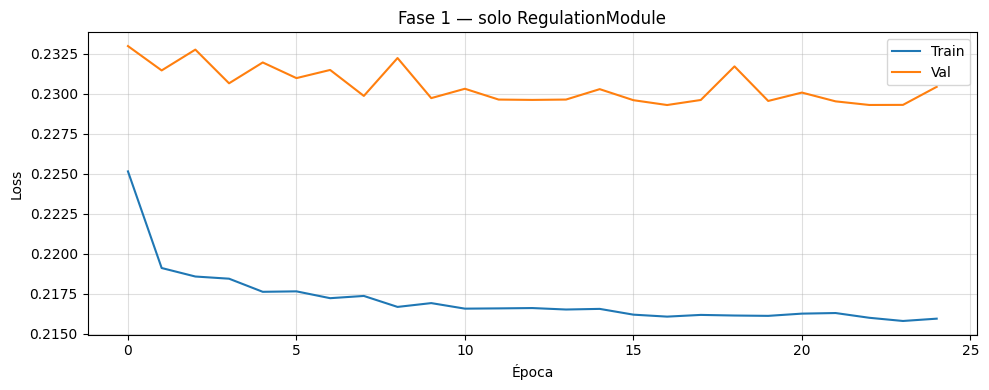

In [52]:
# =============================================================================
# PHASE 1 — Training regulation module
# =============================================================================
for p in regulated_model.base_model.parameters():
    p.requires_grad = False

trainable_p1 = [p for p in regulated_model.parameters() if p.requires_grad]

optimizer_p1  = torch.optim.Adam(trainable_p1, lr=CFG['lr_phase1'], weight_decay=1e-5)
train_losses1, val_losses1 = [], []

print('\n--- Phase 1 ---')
for epoch in range(1, CFG['epochs_phase1'] + 1):
    regulated_model.train()
    tr_loss = 0.0
    for batch in train_loader:
        x_block      = batch['x_block'].squeeze(0).to(device)   # [N, Block_len, F]
        aforo        = batch['aforo'].squeeze(0).to(device)      # [N]
        sim          = batch['sim'].squeeze(0).to(device)        # [N]
        mask         = batch['mask'].squeeze(0).to(device)       # [N] bool

        W = CFG['max_lag'] + CFG['window_gru']

        x_all     = x_block.unfold(1, W, 1).permute(1, 0, 3, 2)  # [D, N, W, F]
        x_climate = x_all[:, :, :, CLIMATE_IDX]                  # [D, N, W, 6]
        dem_log   = x_all[:, :, :, DEM_IDX]                      # [D, N, W]
        dem_phys  = torch.expm1(dem_log)                         # [D, N, W] 

        q_reg_log, q_nat_log = regulated_model(
            x_climate, edge_index, x_static_nat, x_static_full, dem_phys
        )

        q_reg_phys_day   = torch.expm1(q_reg_log)              # [D, N]
        q_reg_phys_month = q_reg_phys_day.mean(dim=0)          # [N] hm3/day prom
        q_reg_month_log  = torch.log1p(q_reg_phys_month)       # [N] log1p

        # Pérdida en aforos
        loss_aforo = (F.mse_loss(q_reg_month_log[mask], aforo[mask])
                      if mask.any() else torch.tensor(0.0, device=device))

        # Pérdida en simulación RREA
        valid_sim = ~torch.isnan(sim)
        loss_sim  = (F.mse_loss(q_reg_month_log[valid_sim], sim[valid_sim])
                     if valid_sim.any() else torch.tensor(0.0, device=device))

        # Penalización física en escala física (no log)
        q_reg_phys = torch.expm1(q_reg_log)  # [D, N]
        q_nat_phys = torch.expm1(q_nat_log)  # [D, N]

        loss = (CFG['lambda_aforo'] * loss_aforo
              + CFG['lambda_sim']   * loss_sim)
        optimizer_p1.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_p1, 1.0)
        optimizer_p1.step()
        tr_loss += loss.item()
    tr_loss /= len(train_loader)

    regulated_model.eval()
    vl_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
                    x_block      = batch['x_block'].squeeze(0).to(device)   # [N, Block_len, F]
                    aforo        = batch['aforo'].squeeze(0).to(device)      # [N]
                    sim          = batch['sim'].squeeze(0).to(device)        # [N]
                    mask         = batch['mask'].squeeze(0).to(device)       # [N] bool
            
                    W = CFG['max_lag'] + CFG['window_gru']
            
                    # Separar clima y demanda
                    x_all     = x_block.unfold(1, W, 1).permute(1, 0, 3, 2)  # [D, N, W, F]
                    x_climate = x_all[:, :, :, CLIMATE_IDX]                  # [D, N, W, 6]
                    dem_log   = x_all[:, :, :, DEM_IDX]                      # [D, N, W]
                    dem_phys  = torch.expm1(dem_log)                         # [D, N, W]
            
                    q_reg_log, q_nat_log = regulated_model(
                        x_climate, edge_index, x_static_nat, x_static_full, dem_phys
                    )
            
                    q_reg_phys_day   = torch.expm1(q_reg_log)              # [D, N]
                    q_reg_phys_month = q_reg_phys_day.mean(dim=0)          # [N] hm3/day prom
                    q_reg_month_log  = torch.log1p(q_reg_phys_month)       # [N] log1p
            
                    loss_aforo = (F.mse_loss(q_reg_month_log[mask], aforo[mask])
                                  if mask.any() else torch.tensor(0.0, device=device))
            
                    valid_sim = ~torch.isnan(sim)
                    loss_sim  = (F.mse_loss(q_reg_month_log[valid_sim], sim[valid_sim])
                                 if valid_sim.any() else torch.tensor(0.0, device=device))
            
                    q_reg_phys = torch.expm1(q_reg_log)  # [D, N]
                    q_nat_phys = torch.expm1(q_nat_log)  # [D, N]
            
                    loss = (CFG['lambda_aforo'] * loss_aforo
                          + CFG['lambda_sim']   * loss_sim)
                    vl_loss += loss.item()
    vl_loss /= len(val_loader)

    train_losses1.append(tr_loss)
    val_losses1.append(vl_loss)
    print(f'Epoch {epoch:02d}/{CFG["epochs_phase1"]} | '
          f'Train: {tr_loss:.5f} | Val: {vl_loss:.5f}')

import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.plot(train_losses1, label='Train'); plt.plot(val_losses1, label='Val')
plt.title('Phase 1 — RegulationModule')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()

## 10. Phase 2: Fine-Tuning ensemble

In [12]:
# =============================================================================
# FASE 2 — Fine-tuning
# =============================================================================
for p in regulated_model.parameters():
    p.requires_grad = True

optimizer_p2 = torch.optim.Adam([
    {'params': regulated_model.base_model.parameters(),
     'lr': CFG['lr_encoder_phase2']},
    {'params': regulated_model.regulation_module.parameters(),
     'lr': CFG['lr_reg_phase2']},
], weight_decay=1e-5)

best_val    = float('inf')
patience_c  = 0
ckpt_path   = 'best_pi_stgat_regulated.pt'
train_losses2, val_losses2 = [], []

print('\n--- Phase 2 ---')
for epoch in range(1, CFG['epochs_phase2'] + 1):
    regulated_model.train()
    tr_loss = 0.0
    for batch in train_loader:
        x_block      = batch['x_block'].squeeze(0).to(device)   # [N, Block_len, F]
        aforo        = batch['aforo'].squeeze(0).to(device)      # [N]
        sim          = batch['sim'].squeeze(0).to(device)        # [N]
        mask         = batch['mask'].squeeze(0).to(device)       # [N] bool

        W = CFG['max_lag'] + CFG['window_gru']

        x_all     = x_block.unfold(1, W, 1).permute(1, 0, 3, 2)  # [D, N, W, F]
        x_climate = x_all[:, :, :, CLIMATE_IDX]                  # [D, N, W, 6]
        dem_log   = x_all[:, :, :, DEM_IDX]                      # [D, N, W]
        dem_phys  = torch.expm1(dem_log)                         # [D, N, W] 

        q_reg_log, q_nat_log = regulated_model(
            x_climate, edge_index, x_static_nat, x_static_full, dem_phys
        )

        q_reg_phys_day   = torch.expm1(q_reg_log)              # [D, N]
        q_reg_phys_month = q_reg_phys_day.mean(dim=0)          # [N] hm3/dia prom
        q_reg_month_log  = torch.log1p(q_reg_phys_month)       # [N] log1p

        loss_aforo = (F.mse_loss(q_reg_month_log[mask], aforo[mask])
                      if mask.any() else torch.tensor(0.0, device=device))

        valid_sim = ~torch.isnan(sim)
        loss_sim  = (F.mse_loss(q_reg_month_log[valid_sim], sim[valid_sim])
                     if valid_sim.any() else torch.tensor(0.0, device=device))

        q_reg_phys = torch.expm1(q_reg_log)  # [D, N]
        q_nat_phys = torch.expm1(q_nat_log)  # [D, N]

        loss = (CFG['lambda_aforo'] * loss_aforo
              + CFG['lambda_sim']   * loss_sim)
        optimizer_p2.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(regulated_model.parameters(), 1.0)
        optimizer_p2.step()
        tr_loss += loss.item()
    tr_loss /= len(train_loader)

    regulated_model.eval()
    vl_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
                    x_block      = batch['x_block'].squeeze(0).to(device)   # [N, Block_len, F]
                    aforo        = batch['aforo'].squeeze(0).to(device)      # [N]
                    sim          = batch['sim'].squeeze(0).to(device)        # [N]
                    mask         = batch['mask'].squeeze(0).to(device)       # [N] bool
            
                    W = CFG['max_lag'] + CFG['window_gru']
            
                    # Separar clima y demanda
                    x_all     = x_block.unfold(1, W, 1).permute(1, 0, 3, 2)  # [D, N, W, F]
                    x_climate = x_all[:, :, :, CLIMATE_IDX]                  # [D, N, W, 6]
                    dem_log   = x_all[:, :, :, DEM_IDX]                      # [D, N, W]
                    dem_phys  = torch.expm1(dem_log)                         # [D, N, W] 
            
                    q_reg_log, q_nat_log = regulated_model(
                        x_climate, edge_index, x_static_nat, x_static_full, dem_phys
                    )
            
                    q_reg_phys_day   = torch.expm1(q_reg_log)              # [D, N]
                    q_reg_phys_month = q_reg_phys_day.mean(dim=0)          # [N] hm3/day prom
                    q_reg_month_log  = torch.log1p(q_reg_phys_month)       # [N] log1p
            
                    loss_aforo = (F.mse_loss(q_reg_month_log[mask], aforo[mask])
                                  if mask.any() else torch.tensor(0.0, device=device))
            
                    valid_sim = ~torch.isnan(sim)
                    loss_sim  = (F.mse_loss(q_reg_month_log[valid_sim], sim[valid_sim])
                                 if valid_sim.any() else torch.tensor(0.0, device=device))
            
                    q_reg_phys = torch.expm1(q_reg_log)  # [D, N]
                    q_nat_phys = torch.expm1(q_nat_log)  # [D, N]
            
                    loss = (CFG['lambda_aforo'] * loss_aforo
                          + CFG['lambda_sim']   * loss_sim)
                    vl_loss += loss.item()
    vl_loss /= len(val_loader)

    train_losses2.append(tr_loss)
    val_losses2.append(vl_loss)
    print(f'Epoch {epoch:03d}/{CFG["epochs_phase2"]} | '
          f'Train: {tr_loss:.5f} | Val: {vl_loss:.5f}')

    if vl_loss < best_val:
        best_val = vl_loss; patience_c = 0
        torch.save(regulated_model.state_dict(), ckpt_path)
        print(f'  → checkpoint saved ({ckpt_path})')
    else:
        patience_c += 1
        if patience_c >= CFG['patience']:
            print(f'Early stopping in epoch {epoch}.')
            break

plt.figure(figsize=(10,4))
plt.plot(train_losses2, label='Train'); plt.plot(val_losses2, label='Val')
plt.title('Phase 2 — Fine-tuning')
plt.xlabel('Época'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()
print(f'Mejor val loss: {best_val:.5f}')


--- Fase 2 ---
Epoch 001/75 | Train: 0.17721 | Val: 0.13446
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 002/75 | Train: 0.12081 | Val: 0.10479
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 003/75 | Train: 0.10371 | Val: 0.09239
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 004/75 | Train: 0.09416 | Val: 0.08253
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 005/75 | Train: 0.08713 | Val: 0.07539
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 006/75 | Train: 0.08133 | Val: 0.06974
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 007/75 | Train: 0.07741 | Val: 0.06613
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 008/75 | Train: 0.07355 | Val: 0.06193
  → checkpoint guardado (best_pi_stgat_regulated.pt)
Epoch 009/75 | Train: 0.07079 | Val: 0.05896
  → checkpoint guardado (best_pi_stgat_regulated.pt)


KeyboardInterrupt: 

## 11. Test set evaluation

In [20]:
# =============================================================================
# Test set evaluation
# =============================================================================
regulated_model.load_state_dict(torch.load(ckpt_path, map_location=device))
regulated_model.base_model.M_lag = regulated_model.base_model.M_lag.to(device)
regulated_model.eval()

preds_list, aforos_list, masks_list, sims_list = [], [], [], []

with torch.no_grad():
    for batch in test_loader:
        x_block = batch['x_block'].squeeze(0).to(device)
        aforo   = batch['aforo'].squeeze(0).to(device)
        sim     = batch['sim'].squeeze(0).to(device)
        mask    = batch['mask'].squeeze(0).to(device)

        W         = CFG['max_lag'] + CFG['window_gru']
        x_all     = x_block.unfold(1, W, 1).permute(1, 0, 3, 2)
        x_climate = x_all[:, :, :, CLIMATE_IDX]
        dem_phys  = torch.expm1(x_all[:, :, :, DEM_IDX])

        q_reg_log, _ = regulated_model(
            x_climate, edge_index, x_static_nat, x_static_full, dem_phys
        )
        q_reg_month = torch.log1p(torch.expm1(q_reg_log).mean(dim=0))  # [N]

        preds_list.append(q_reg_month.cpu().numpy())
        aforos_list.append(aforo.cpu().numpy())
        masks_list.append(mask.cpu().numpy())
        sims_list.append(sim.cpu().numpy())

preds_monthly   = np.stack(preds_list,  axis=0)  # [T_test, N]
targets_monthly = np.stack(aforos_list, axis=0)
masks_monthly   = np.stack(masks_list,  axis=0)
sims_monthly    = np.stack(sims_list,   axis=0)

preds_phys   = np.expm1(preds_monthly)
targets_phys = np.expm1(targets_monthly)
sims_phys    = np.expm1(sims_monthly)

metrics_rows = []
for i, mass in enumerate(mass_list):
    col_mask = masks_monthly[:, i]
    if not col_mask.any(): continue
    t = targets_phys[col_mask, i]
    p = preds_phys[col_mask, i]
    metrics_rows.append({
        'Water_Body_Code' : mass,
        'Valid_Months'    : int(col_mask.sum()),
        'NSE'             : calculate_nse(t, p),
        'KGE'             : calculate_kge(t, p),
        'RMSE_hm3_dia'    : np.sqrt(mean_squared_error(t, p)),
        'MAE_hm3_dia'     : np.mean(np.abs(t - p)),
        'PBIAS_percent'   : 100*np.sum(p-t)/(np.sum(t)+1e-8),
    })

import os
os.makedirs('resultados_pp_runoff', exist_ok=True)
df_metrics = pd.DataFrame(metrics_rows)
df_metrics.to_csv(
    'resultados_pp_runoff/pi_stgat_regulated_metrics.csv', index=False, sep=';')

print('\n=== Test Set ===')
print(df_metrics.to_string(index=False))
print(f'\nNSE mean : {df_metrics["NSE"].mean():.3f}')
print(f'KGE mean: {df_metrics["KGE"].mean():.3f}')

C:\Users\usuario\AppData\Local\Temp\ipykernel_9188\2906428616.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  regulated_model.load_state_dict(torch.load(ckpt_path, map_l


=== Test Set — Nodos con aforo ===
Water_Body_Code  Valid_Months         NSE        KGE  RMSE_hm3_dia  MAE_hm3_dia  PBIAS_percent
         18-03_            22   -1.017620   0.164240      0.205393     0.151724  -4.194808e+01
         18-07_            22   -0.504901   0.135253      0.965265     0.739281   7.010367e+01
         18-10_            22    0.264554   0.523738      0.294869     0.223171   1.745535e+01
   18-14-01-05_            22    0.000000   0.000000      0.128216     0.118644   2.610179e+10
   18-14-01-07_            22    0.000000   0.000000      0.105531     0.100217   2.204779e+10
   18-21-01-07_            22   -0.044648   0.195968      0.330308     0.247519   5.131245e+01
         18-25_            22    0.836043   0.742519      0.338990     0.302233   1.974873e+01
   18-29-01-02_            22    0.267813   0.249136      0.128443     0.112312   3.501171e+01
   18-32-01-06_            22 -242.063873 -13.758572      0.135006     0.128045   1.423729e+03

NSE medio : -

## 12. Validation plots

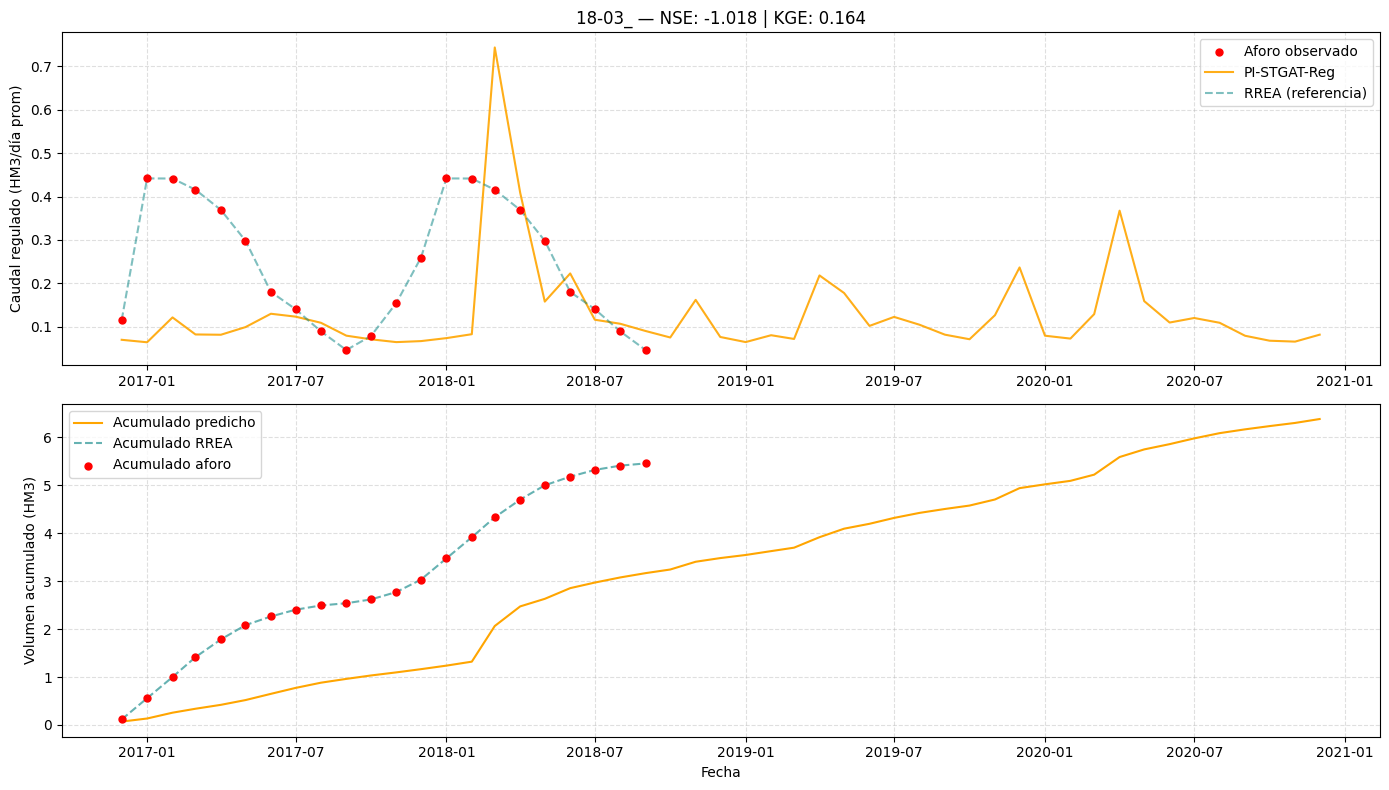

  18-03_: NSE=-1.018  KGE=0.164


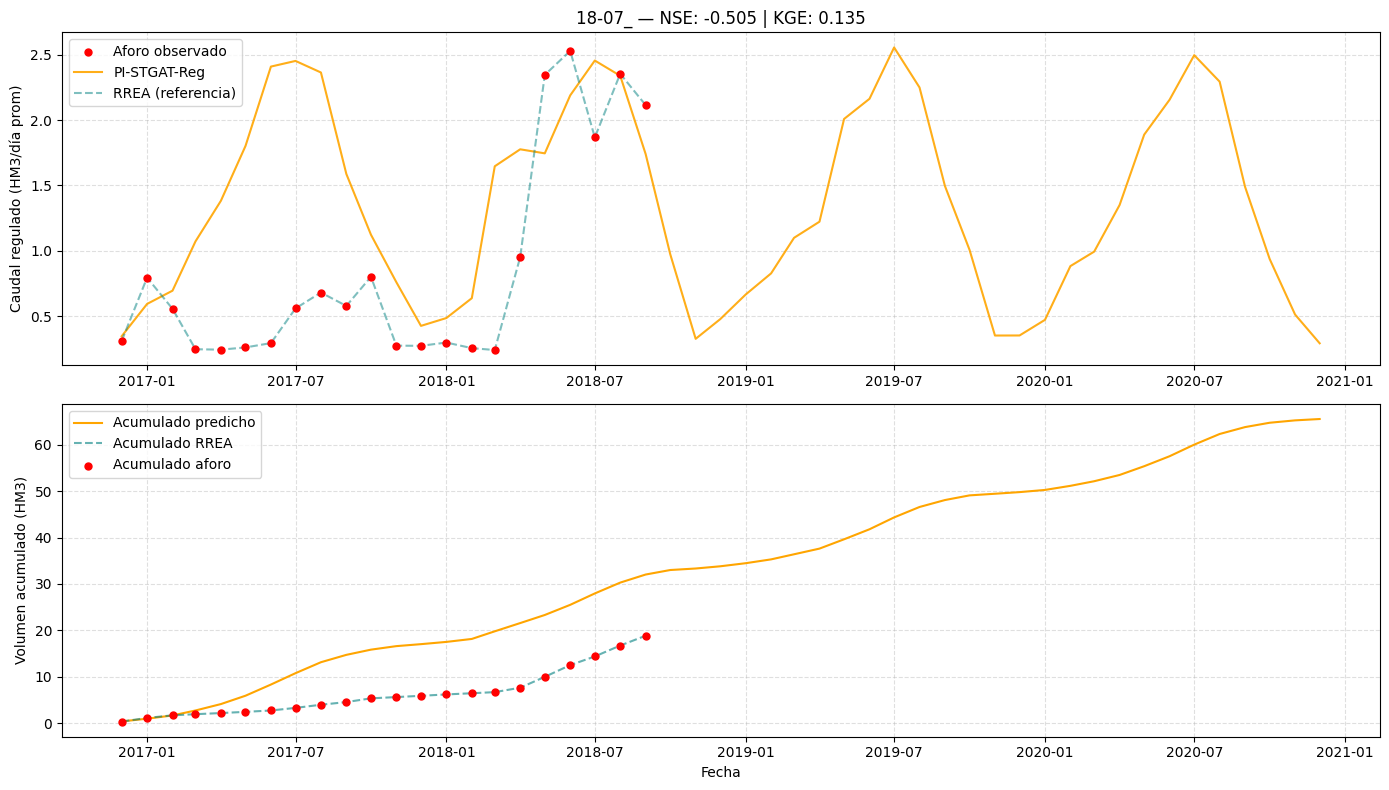

  18-07_: NSE=-0.505  KGE=0.135


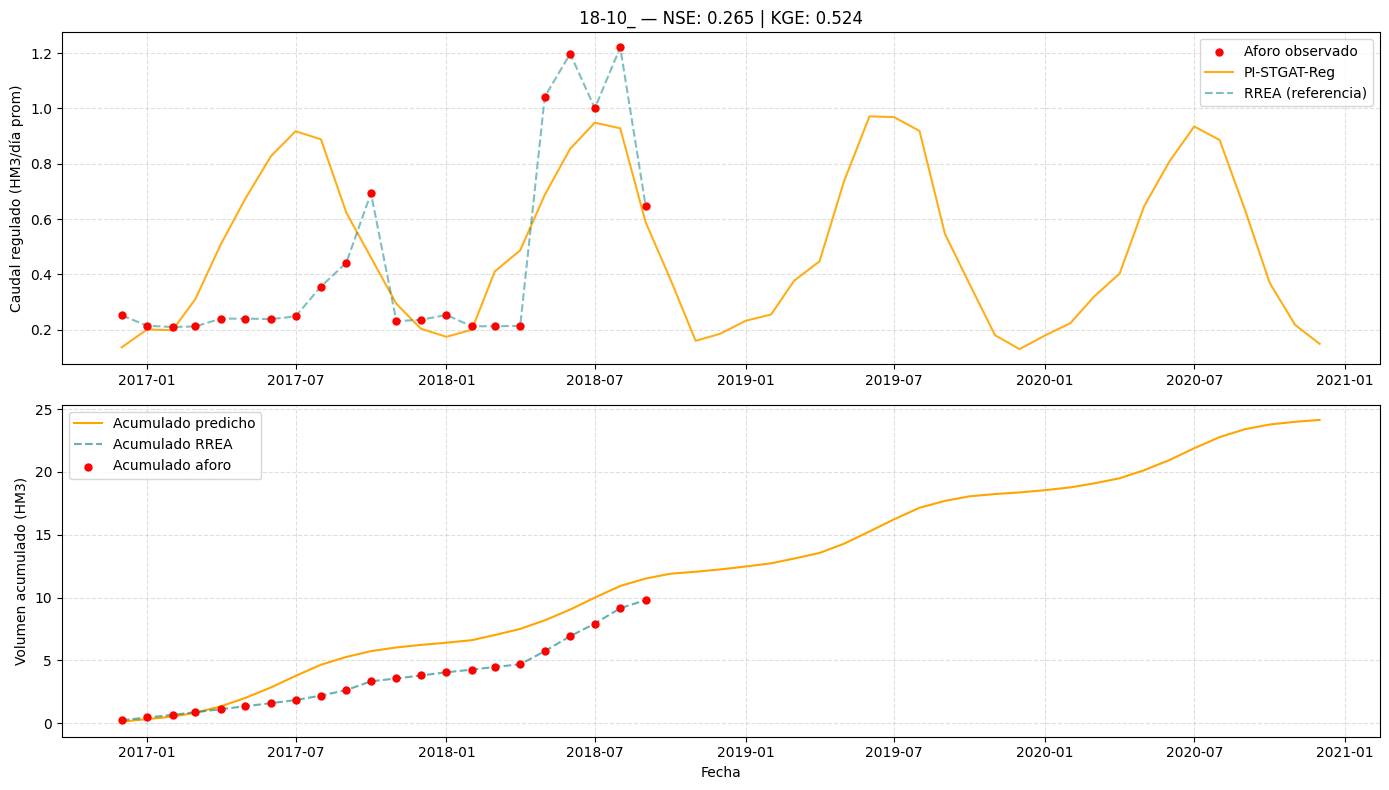

  18-10_: NSE=0.265  KGE=0.524


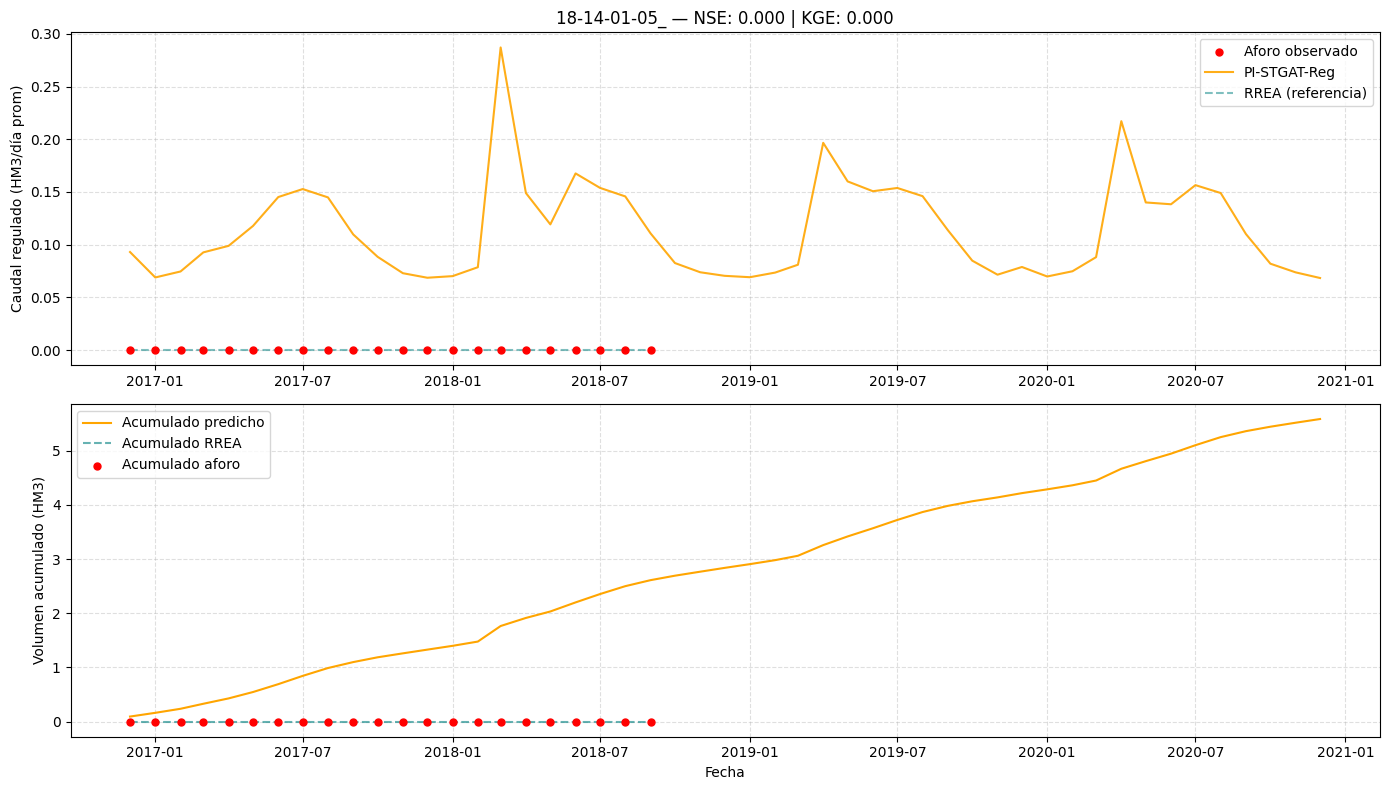

  18-14-01-05_: NSE=0.000  KGE=0.000


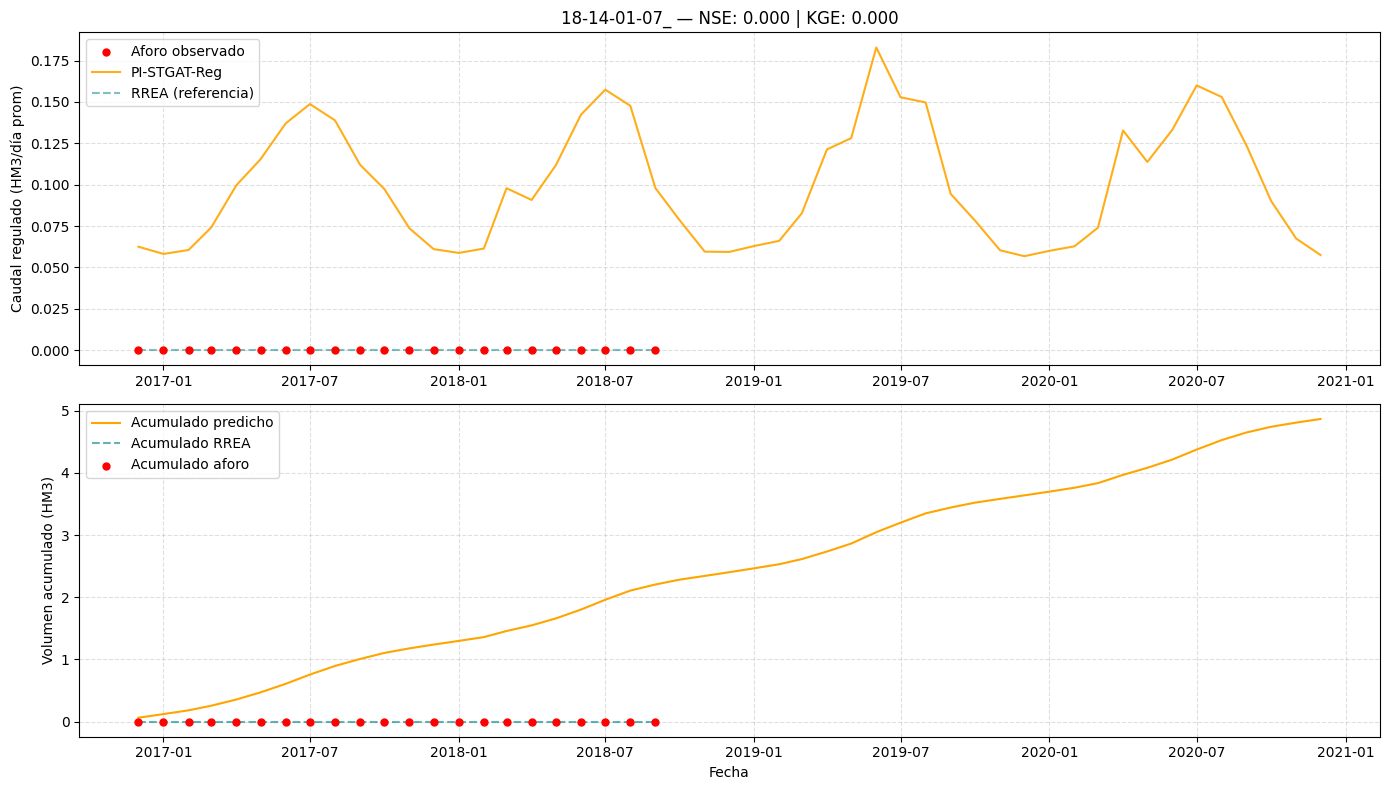

  18-14-01-07_: NSE=0.000  KGE=0.000


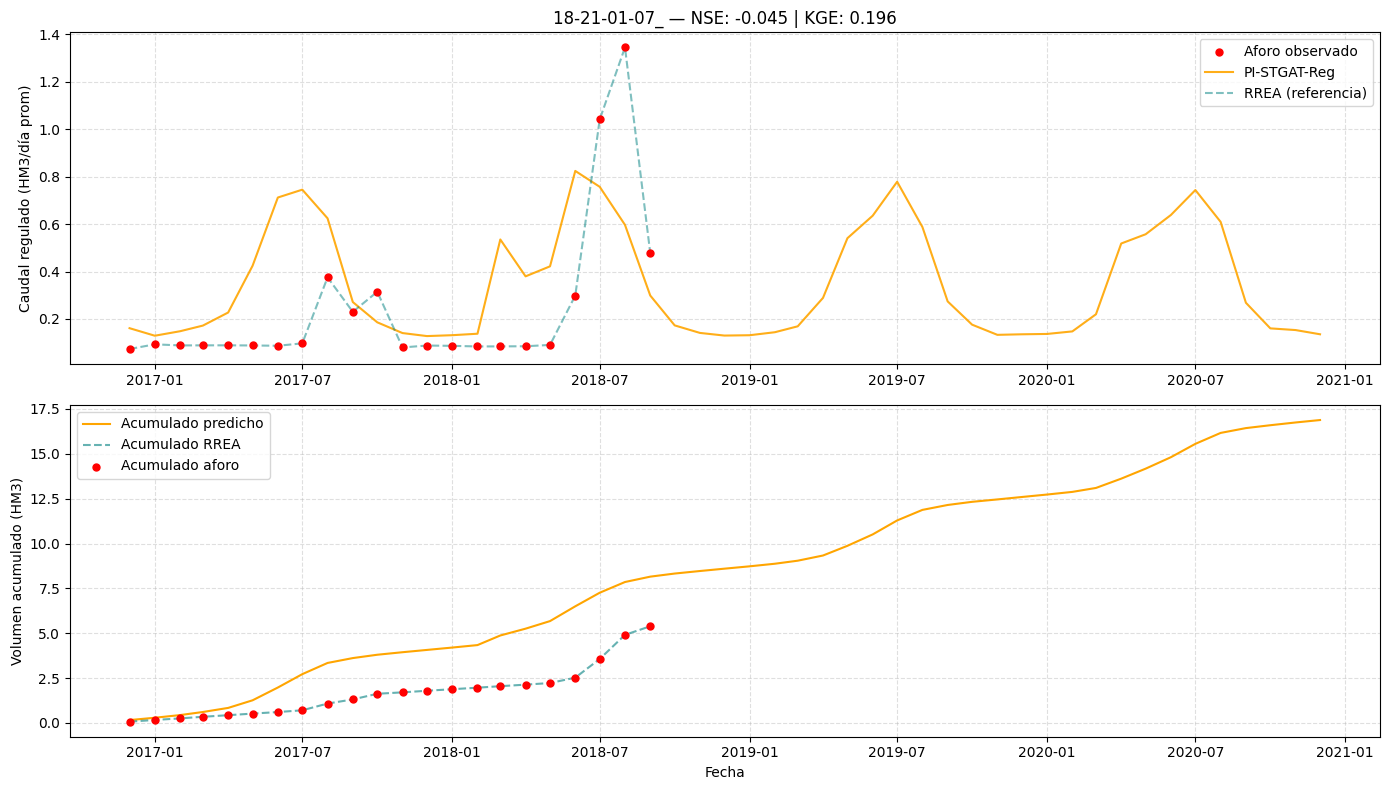

  18-21-01-07_: NSE=-0.045  KGE=0.196


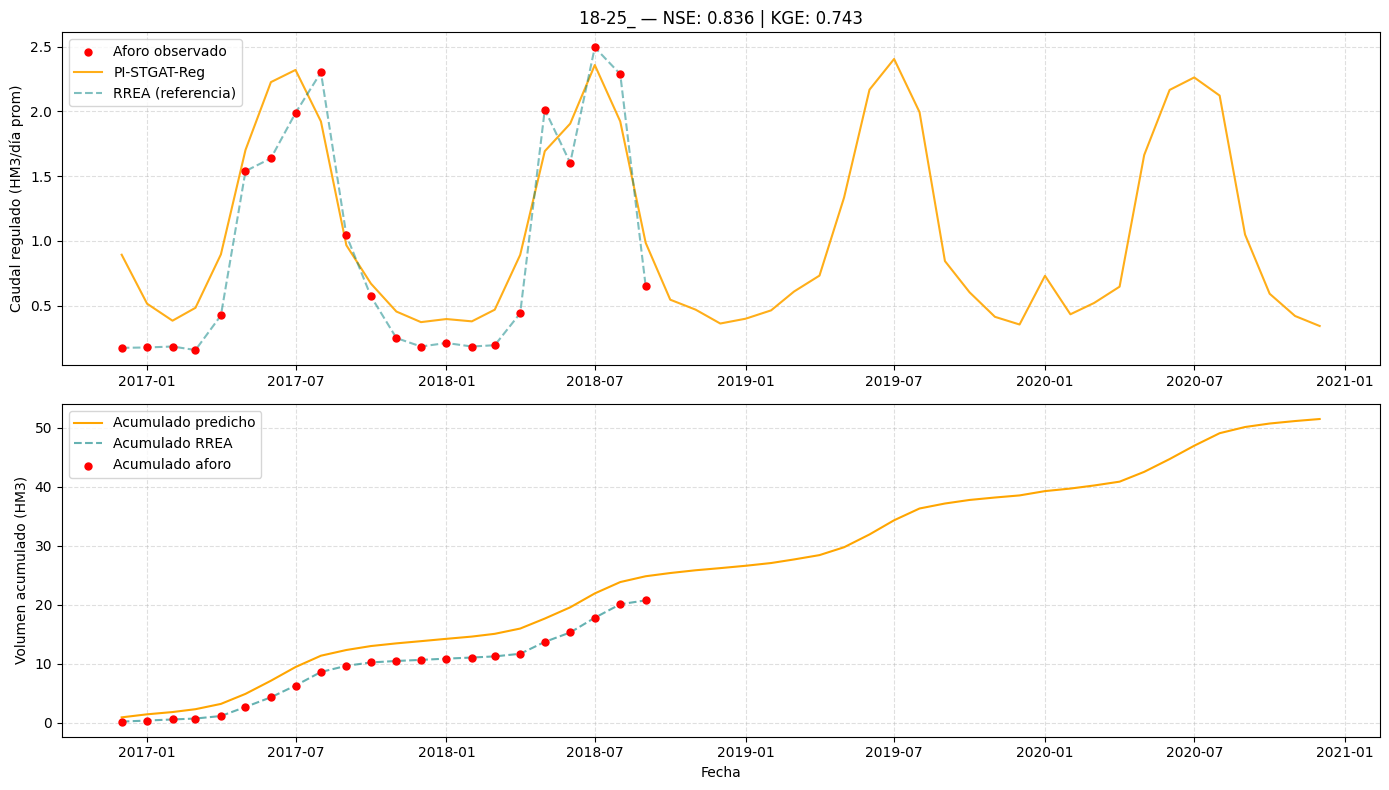

  18-25_: NSE=0.836  KGE=0.743


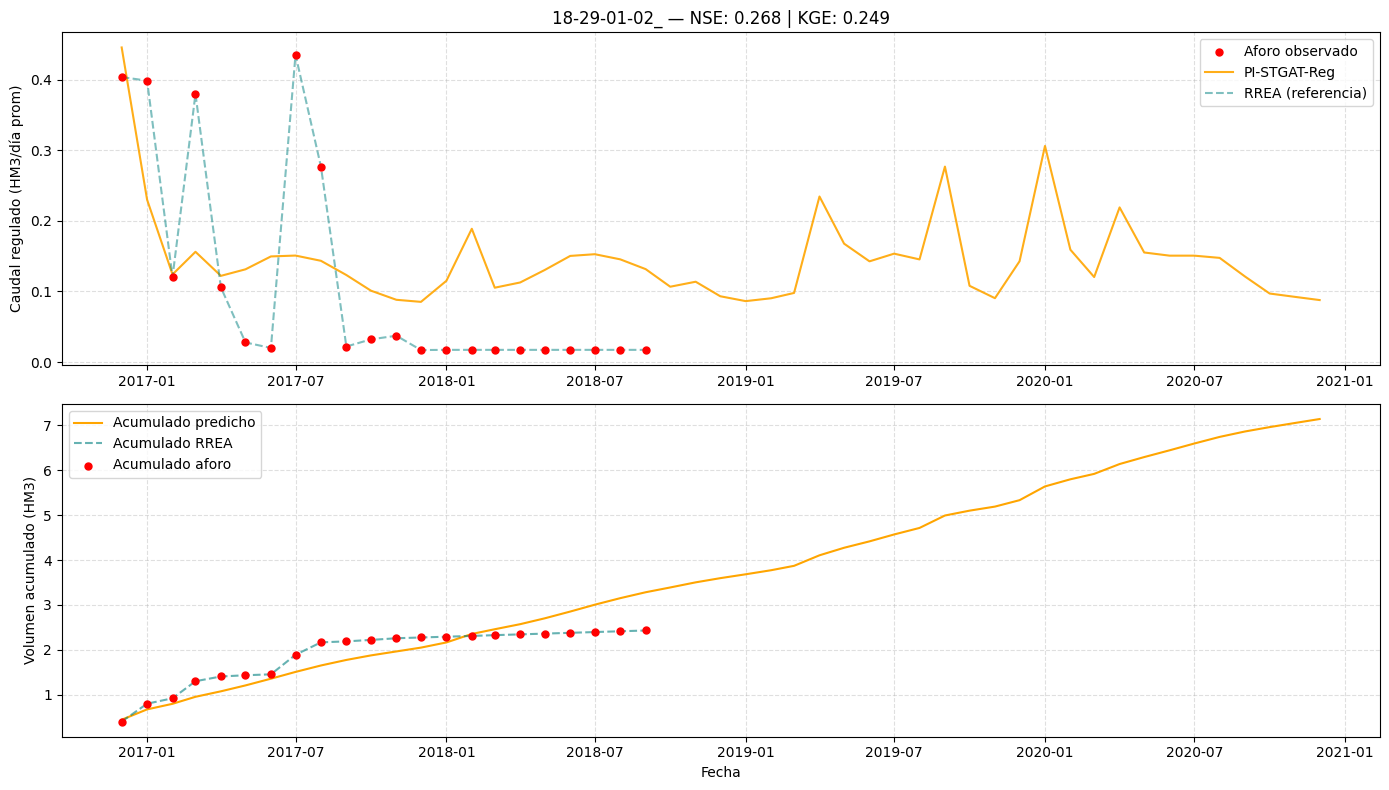

  18-29-01-02_: NSE=0.268  KGE=0.249


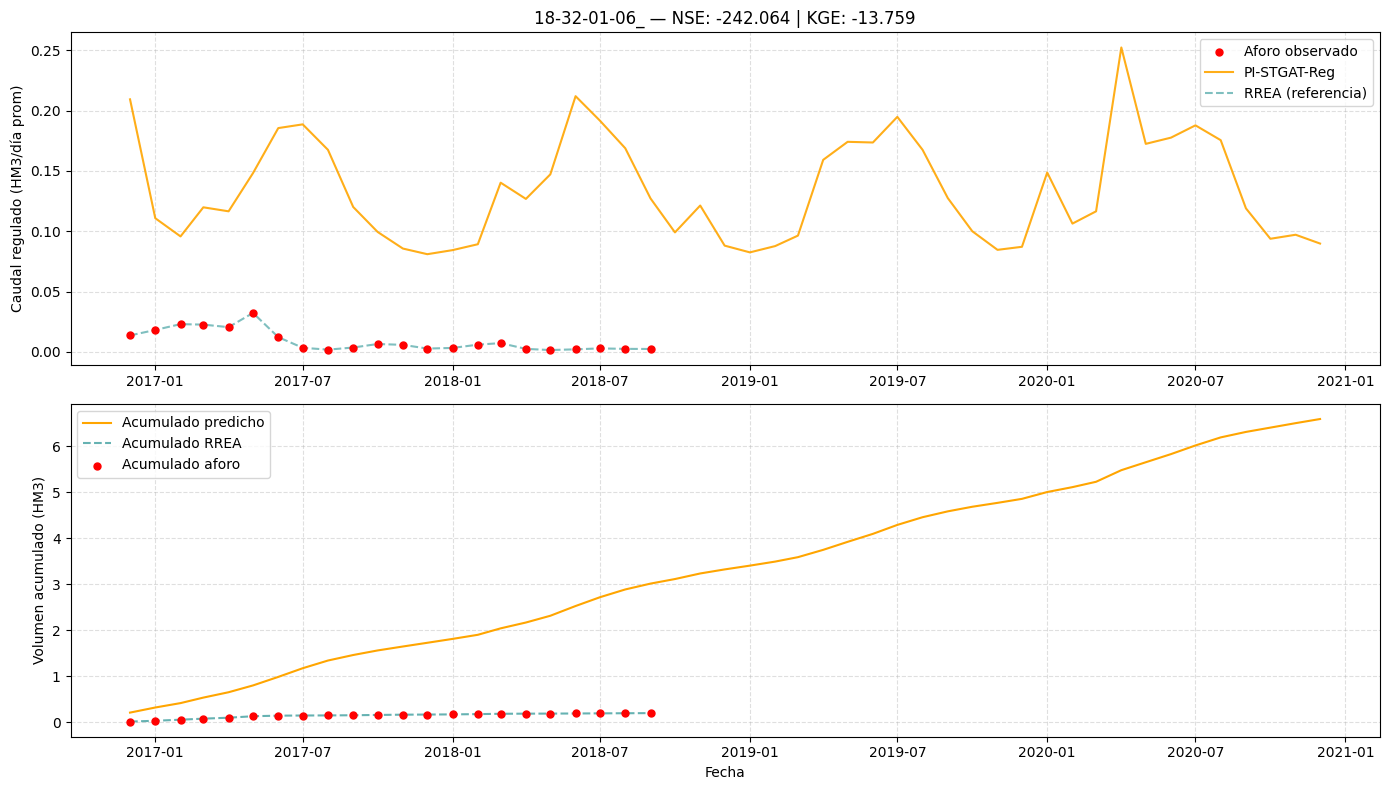

  18-32-01-06_: NSE=-242.064  KGE=-13.759


In [22]:
out_dir = 'plots/pi_stgat_regulated_validation'
os.makedirs(out_dir, exist_ok=True)

n_test     = len(test_ds)
test_dates = [pd.to_datetime(d)
              for d in metadata['dates_mensuales'][-(n_test):]]

for i, mass in enumerate(mass_list):
    col_mask = masks_monthly[:, i]
    if not col_mask.any(): continue

    row     = df_metrics[df_metrics['Water_Body_Code'] == mass].iloc[0]
    obs     = targets_phys[:, i]
    pred    = preds_phys[:, i]
    sim_ref = sims_phys[:, i]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    # Hydrogram
    axes[0].scatter(np.array(test_dates)[col_mask], obs[col_mask],
                    color='red', label='Observed', zorder=5, s=25)
    axes[0].plot(test_dates, pred,
                 label='PI-STGAT-Reg', color='orange', alpha=0.9)
    axes[0].plot(test_dates, sim_ref,
                 label='Observed', color='teal', linestyle='--', alpha=0.5)
    axes[0].set_title(f'{mass} — NSE: {row["NSE"]:.3f} | KGE: {row["KGE"]:.3f}')
    axes[0].set_ylabel('Regulated streamflow (HM3/day prom)')
    axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.4)

    # Volumen acumulado
    axes[1].plot(test_dates, np.cumsum(pred),
                 label='Acumulated predict', color='orange')
    axes[1].scatter(np.array(test_dates)[col_mask],
                    np.cumsum(obs)[col_mask],
                    color='red', label='Accumulated observed', zorder=5, s=25)
    axes[1].set_ylabel('Accumulated volume (HM3)'); axes[1].set_xlabel('Dates')
    axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(f'{out_dir}/{mass}.png', dpi=300)
    plt.show()
    print(f'  {mass}: NSE={row["NSE"]:.3f}  KGE={row["KGE"]:.3f}')